# AeroPredict — Notebook definitivo de modelado

**TFM Data Science & Analytics**  
**Entorno:** R en Google Colab · **Datos:** PostgreSQL / Neon (`gold.feature_store`)

## Objetivo

Construir un sistema predictivo de dos etapas:

1. **Clasificación — Regresión logística binomial:** estima la probabilidad de que un vuelo tenga un retraso significativo (15 minutos o más).
2. **Regresión — Gradient Boosting Machine (GBM) con objetivo `log1p`:** estima los minutos de retraso cuando la primera etapa clasifica el vuelo como retrasado.

Este notebook conserva únicamente el flujo final: conexión segura, carga y preparación, CATDES, partición temporal, entrenamiento de los dos modelos seleccionados, evaluación, interpretación y exportación. Los experimentos de modelos descartados y diagnósticos exploratorios no forman parte de esta versión.

> **Importante:** `retraso_minutos` se construye a partir de `estimated_local - scheduled_local`. Por tanto, la etiqueta representa el retraso derivado de esa estimación y no necesariamente un retraso real observado por la operación aeroportuaria.


## 1. Decisiones finales de modelado

| Etapa | Modelo definitivo | Objetivo | Resultado |
|---|---|---|---|
| 1. Clasificación | Regresión logística binomial | `retraso_15_min` | Probabilidad y clase RETRASO / NO_RETRASO |
| 2. Regresión | GBM gaussiano sobre `log1p(retraso_minutos)` | `retraso_minutos`, solo para positivos | Minutos estimados |

El umbral de clasificación se selecciona con VALIDACIÓN y se mantiene fijo al evaluar TEST. El conjunto TEST queda reservado para la evaluación final.

No se entrenan aquí árboles, Random Forest ni variantes experimentales: se documentan los dos modelos elegidos para el flujo de AeroPredict.


## 2. Preparar el entorno

Se instalan las dependencias necesarias para conectar con PostgreSQL/Neon, preparar los datos, entrenar los modelos y realizar el análisis descriptivo CATDES.

In [1]:
paquetes <- c(
  "DBI", "RPostgres", "dplyr", "httr", "getPass", "gbm", "FactoMineR"
)

instalados <- rownames(installed.packages())
faltantes <- setdiff(paquetes, instalados)

if (length(faltantes) > 0) {
  install.packages(faltantes, repos = "https://cloud.r-project.org")
}

suppressPackageStartupMessages({
  library(DBI)
  library(RPostgres)
  library(dplyr)
  library(gbm)
})

set.seed(123)
cat("Entorno preparado.\n")

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘colorspace’, ‘fracdiff’, ‘lmtest’, ‘timeDate’, ‘urca’, ‘zoo’, ‘RcppArmadillo’, ‘cowplot’, ‘Deriv’, ‘forecast’, ‘rbibutils’, ‘doBy’, ‘SparseM’, ‘MatrixModels’, ‘Rdpack’, ‘minqa’, ‘nloptr’, ‘reformulas’, ‘RcppEigen’, ‘lazyeval’, ‘carData’, ‘abind’, ‘Formula’, ‘pbkrtest’, ‘quantreg’, ‘lme4’, ‘crosstalk’, ‘estimability’, ‘mvtnorm’, ‘numDeriv’, ‘showtextdb’, ‘car’, ‘DT’, ‘ellipse’, ‘emmeans’, ‘flashClust’, ‘ggrepel’, ‘irlba’, ‘leaps’, ‘multcompView’, ‘scatterplot3d’, ‘showtext’, ‘sysfonts’




Entorno preparado.


## 3. Conectar a PostgreSQL / Neon de forma segura

La URI se lee desde la variable de entorno `AEROPREDICT_DATABASE_URL` o mediante entrada oculta. **No escribir la URI, contraseña ni claves en el notebook.** Antes de subir el archivo a Git, revisar también el historial de Git y los secretos configurados en el repositorio.

In [2]:
if (nzchar(Sys.getenv("AEROPREDICT_DATABASE_URL"))) {
  postgres_uri <- Sys.getenv("AEROPREDICT_DATABASE_URL")
} else {
  postgres_uri <- getPass::getPass(
    "Pega la URI completa de PostgreSQL/Neon (entrada oculta): "
  )
}

if (!nzchar(postgres_uri)) {
  stop("No se proporcionó la URI de PostgreSQL.")
}

partes_uri <- httr::parse_url(postgres_uri)
if (is.null(partes_uri$hostname) || is.null(partes_uri$username) ||
    is.null(partes_uri$password) || is.null(partes_uri$path)) {
  stop("La URI no contiene host, usuario, contraseña y nombre de base de datos.")
}

puerto_pg <- if (is.null(partes_uri$port)) 5432L else as.integer(partes_uri$port)
base_pg <- sub("^/", "", partes_uri$path)

con <- DBI::dbConnect(
  RPostgres::Postgres(),
  host = partes_uri$hostname,
  port = puerto_pg,
  dbname = base_pg,
  user = utils::URLdecode(partes_uri$username),
  password = utils::URLdecode(partes_uri$password),
  sslmode = "require"
)

if (!DBI::dbIsValid(con)) {
  stop("No se pudo validar la conexión a PostgreSQL.")
}

# Eliminar la URI y sus componentes de la sesión tras conectar.
rm(postgres_uri, partes_uri, puerto_pg, base_pg)
cat("Conexión segura validada. La URI no se ha mostrado.\n")
print(DBI::dbGetQuery(con, "SELECT 1 AS conexion_ok"))

Pega la URI completa de PostgreSQL/Neon (entrada oculta): ··········
Conexión segura validada. La URI no se ha mostrado.
  conexion_ok
1           1


## 4. Cargar los datos y definir el objetivo

Se consulta `gold.feature_store` hasta el 19/10/2026. La variable objetivo binaria se deriva de `retraso_minutos >= 15`. Los identificadores se conservan para trazabilidad, pero no forman parte de los predictores.

In [3]:
fecha_corte_datos <- as.Date("2026-10-19")

variables_predictoras <- c(
  "hora_vuelo", "dia_semana", "airline_iata", "other_airport_iata",
  "temperatura_metar", "punto_rocio_metar", "relh"
)

variables_categoricas <- c(
  "hora_vuelo", "dia_semana", "airline_iata", "other_airport_iata"
)

sql_modelado <- "
SELECT
    aena_airport_iata,
    flight_number,
    flight_type,
    scheduled_local,
    hora_vuelo,
    dia_semana,
    airline_iata,
    other_airport_iata,
    temperatura_metar,
    punto_rocio_metar,
    relh,
    retraso_minutos
FROM gold.feature_store
WHERE DATE(scheduled_local) <= DATE '2026-10-19'
  AND retraso_minutos IS NOT NULL;
"

datos_brutos <- DBI::dbGetQuery(con, sql_modelado)
if (nrow(datos_brutos) == 0) {
  stop("La consulta no devolvió registros para modelar.")
}

df_modelado <- datos_brutos %>%
  mutate(
    fecha_vuelo = as.Date(substr(as.character(scheduled_local), 1, 10)),
    retraso_minutos = as.numeric(as.character(retraso_minutos)),
    temperatura_metar = as.numeric(as.character(temperatura_metar)),
    punto_rocio_metar = as.numeric(as.character(punto_rocio_metar)),
    relh = as.numeric(as.character(relh)),
    across(all_of(variables_categoricas), as.character),
    retraso_15_min = as.integer(retraso_minutos >= 15)
  ) %>%
  arrange(fecha_vuelo)

filas_antes_limpieza <- nrow(df_modelado)
columnas_modelado <- c(
  variables_predictoras, "fecha_vuelo", "retraso_minutos", "retraso_15_min"
)
filas_completas <- complete.cases(df_modelado[, columnas_modelado])
filas_excluidas_na <- sum(!filas_completas)
df_modelado <- df_modelado[filas_completas, , drop = FALSE]

if (nrow(df_modelado) == 0) {
  stop("No quedan filas completas tras revisar predictores y objetivo.")
}
if (anyNA(df_modelado$fecha_vuelo)) {
  stop("Hay fechas de vuelo que no se pudieron interpretar.")
}

cat("Registros consultados:", filas_antes_limpieza, "\n")
cat("Registros excluidos por valores ausentes/no válidos:", filas_excluidas_na, "\n")
cat("Registros utilizables:", nrow(df_modelado), "\n")
cat("Periodo:", as.character(min(df_modelado$fecha_vuelo)), "a",
    as.character(max(df_modelado$fecha_vuelo)), "\n")
cat("Distribución del objetivo (0 = <15 min; 1 = >=15 min):\n")
print(table(df_modelado$retraso_15_min))


Registros consultados: 83407 
Registros excluidos por valores ausentes/no válidos: 0 
Registros utilizables: 83407 
Periodo: 2026-08-01 a 2026-10-19 
Distribución del objetivo (0 = <15 min; 1 = >=15 min):

    0     1 
70341 13066 


## 5. Controles de calidad y partición temporal

Se comprueba la clave lógica de vuelo en la tabla Gold. La separación se realiza cronológicamente por fecha, aproximadamente 60 % TRAIN, 20 % VALIDACIÓN y 20 % TEST FINAL. El conjunto TEST queda reservado para la evaluación final.

In [4]:
sql_duplicados <- "
SELECT
    COUNT(*) AS total_registros,
    COUNT(DISTINCT (
        aena_airport_iata,
        UPPER(TRIM(flight_number)),
        LOWER(TRIM(flight_type)),
        scheduled_local
    )) AS vuelos_unicos
FROM gold.feature_store
WHERE DATE(scheduled_local) <= DATE '2026-10-19'
  AND retraso_minutos IS NOT NULL;
"

control_duplicados <- DBI::dbGetQuery(con, sql_duplicados)
cat("Control de duplicados por clave lógica:\n")
print(control_duplicados)

DBI::dbDisconnect(con)
cat("Conexión a PostgreSQL cerrada.\n")

# Partición cronológica: 60 % TRAIN, 20 % VALIDACIÓN y 20 % TEST FINAL.
fechas <- sort(unique(df_modelado$fecha_vuelo))
if (length(fechas) < 10) {
  stop("No hay suficientes fechas distintas para una separación temporal.")
}

corte_validacion <- fechas[floor(length(fechas) * 0.60)]
corte_test <- fechas[floor(length(fechas) * 0.80)]

if (corte_validacion >= corte_test) {
  stop("Las fechas de corte no permiten separar TRAIN, VALIDACIÓN y TEST.")
}

datos_train <- df_modelado %>% filter(fecha_vuelo < corte_validacion)
datos_val <- df_modelado %>%
  filter(fecha_vuelo >= corte_validacion, fecha_vuelo < corte_test)
datos_test_final <- df_modelado %>% filter(fecha_vuelo >= corte_test)

if (nrow(datos_train) == 0 || nrow(datos_val) == 0 || nrow(datos_test_final) == 0) {
  stop("Uno de los conjuntos temporales quedó vacío.")
}

resumen_particion <- data.frame(
  conjunto = c("TRAIN", "VALIDACIÓN", "TEST FINAL"),
  filas = c(nrow(datos_train), nrow(datos_val), nrow(datos_test_final)),
  desde = c(min(datos_train$fecha_vuelo), min(datos_val$fecha_vuelo), min(datos_test_final$fecha_vuelo)),
  hasta = c(max(datos_train$fecha_vuelo), max(datos_val$fecha_vuelo), max(datos_test_final$fecha_vuelo))
)
print(resumen_particion, row.names = FALSE)

cat("\nDistribución de la etiqueta por partición:\n")
print(dplyr::bind_rows(
  datos_train %>% count(retraso_15_min) %>% mutate(conjunto = "TRAIN"),
  datos_val %>% count(retraso_15_min) %>% mutate(conjunto = "VALIDACIÓN"),
  datos_test_final %>% count(retraso_15_min) %>% mutate(conjunto = "TEST FINAL")
) %>% select(conjunto, retraso_15_min, n))


Control de duplicados por clave lógica:
  total_registros vuelos_unicos
1           83407         83407
Conexión a PostgreSQL cerrada.
   conjunto filas      desde      hasta
      TRAIN 44495 2026-08-01 2026-09-22
 VALIDACIÓN 14173 2026-09-23 2026-10-12
 TEST FINAL 24739 2026-10-13 2026-10-19

Distribución de la etiqueta por partición:
    conjunto retraso_15_min     n
1      TRAIN              0 38304
2      TRAIN              1  6191
3 VALIDACIÓN              0 13282
4 VALIDACIÓN              1   891
5 TEST FINAL              0 18755
6 TEST FINAL              1  5984


## 6. Preprocesamiento: reglas aprendidas sin fuga de información

- Aerolíneas y aeropuertos con menos de dos observaciones en TRAIN se agrupan en `OTRA`.
- `hora_vuelo` usa el dominio conocido 0–23 y `dia_semana` el dominio 1–7. Se comprueba que no existan valores fuera de esos dominios.
- Las columnas indicadoras se construyen con `model.matrix()` y se alinean siempre con las columnas aprendidas en TRAIN.

In [5]:
dominios_temporales <- list(
  hora_vuelo = as.character(0:23),
  dia_semana = as.character(1:7)
)

preparar_categorias_temporal <- function(
  train, validacion, test,
  variables_categoricas,
  variables_agrupadas = c("airline_iata", "other_airport_iata"),
  frecuencia_minima = 2
) {
  conjuntos <- list(train = train, validacion = validacion, test = test)
  reglas <- list()

  # Categorías de alta cardinalidad: frecuencias calculadas solo en TRAIN.
  for (v in intersect(variables_agrupadas, variables_categoricas)) {
    valores_train <- as.character(conjuntos$train[[v]])
    frecuencias <- table(valores_train[!is.na(valores_train)])
    niveles_frecuentes <- names(frecuencias[frecuencias >= frecuencia_minima])

    niveles_finales <- unique(c(niveles_frecuentes, "OTRA"))

    for (nombre_conjunto in names(conjuntos)) {
      valores <- as.character(conjuntos[[nombre_conjunto]][[v]])
      valores[is.na(valores) | !(valores %in% niveles_frecuentes)] <- "OTRA"
      conjuntos[[nombre_conjunto]][[v]] <- factor(
        valores, levels = niveles_finales
      )
    }

    reglas[[v]] <- list(
      tipo = "frecuencia",
      niveles_frecuentes = niveles_frecuentes,
      niveles_finales = niveles_finales,
      frecuencia_minima = frecuencia_minima
    )
  }

  # Variables temporales: dominios conocidos, no solo niveles observados.
  for (v in setdiff(variables_categoricas, variables_agrupadas)) {
    niveles <- dominios_temporales[[v]]

    if (is.null(niveles)) {
      niveles <- sort(unique(as.character(conjuntos$train[[v]])))
    }

    for (nombre_conjunto in names(conjuntos)) {
      valores <- as.character(conjuntos[[nombre_conjunto]][[v]])
      valores_invalidos <- !is.na(valores) & !(valores %in% niveles)

      if (any(valores_invalidos)) {
        stop(paste0(
          "La variable ", v, " contiene valores fuera del dominio en ",
          nombre_conjunto, "."
        ))
      }

      conjuntos[[nombre_conjunto]][[v]] <- factor(valores, levels = niveles)
    }

    reglas[[v]] <- list(tipo = "dominio", niveles_finales = niveles)
  }

  list(
    train = conjuntos$train,
    validacion = conjuntos$validacion,
    test = conjuntos$test,
    reglas = reglas
  )
}

crear_matriz_predictores <- function(datos, formula_x, columnas = NULL) {
  X <- stats::model.matrix(formula_x, data = datos)
  X <- X[, colnames(X) != "(Intercept)", drop = FALSE]

  if (is.null(columnas)) {
    if (ncol(X) == 0) stop("No se generaron variables indicadoras.")
    constantes <- vapply(seq_len(ncol(X)), function(j) {
      length(unique(X[, j])) <= 1
    }, logical(1))
    return(X[, !constantes, drop = FALSE])
  }

  X_alineada <- matrix(
    0,
    nrow = nrow(datos),
    ncol = length(columnas),
    dimnames = list(NULL, columnas)
  )
  comunes <- intersect(columnas, colnames(X))
  X_alineada[, comunes] <- X[, comunes, drop = FALSE]
  X_alineada
}

formula_x <- stats::as.formula(
  paste("~", paste(variables_predictoras, collapse = " + "))
)
cat("Funciones de preprocesamiento preparadas.\n")

Funciones de preprocesamiento preparadas.


## 7. Preparar matrices de clasificación

Se aprende el preprocesamiento con TRAIN y se aplica a VALIDACIÓN y TEST. El objetivo no entra en la matriz de predictores.

In [6]:
prep_clasificacion <- preparar_categorias_temporal(
  datos_train,
  datos_val,
  datos_test_final,
  variables_categoricas = variables_categoricas,
  frecuencia_minima = 2
)

train_clas <- prep_clasificacion$train
val_clas <- prep_clasificacion$validacion
test_clas <- prep_clasificacion$test

x_train <- crear_matriz_predictores(train_clas, formula_x)
columnas_x_clasificacion <- colnames(x_train)
x_val <- crear_matriz_predictores(val_clas, formula_x, columnas_x_clasificacion)
x_test <- crear_matriz_predictores(test_clas, formula_x, columnas_x_clasificacion)

y_train <- as.integer(train_clas$retraso_15_min)
y_val <- as.integer(val_clas$retraso_15_min)
y_test <- as.integer(test_clas$retraso_15_min)

stopifnot(
  identical(colnames(x_train), colnames(x_val)),
  identical(colnames(x_train), colnames(x_test)),
  nrow(x_train) == length(y_train),
  nrow(x_val) == length(y_val),
  nrow(x_test) == length(y_test)
)

cat("TRAIN:", nrow(x_train), "filas x", ncol(x_train), "columnas\n")
cat("VALIDACIÓN:", nrow(x_val), "filas\n")
cat("TEST FINAL:", nrow(x_test), "filas\n")

TRAIN: 44495 filas x 457 columnas
VALIDACIÓN: 14173 filas
TEST FINAL: 24739 filas


## 8. Análisis descriptivo CATDES (TRAIN)

`catdes()` de **FactoMineR** describe qué categorías y qué variables cuantitativas caracterizan las clases de una variable cualitativa. Aquí se utiliza `retraso_15_min` como variable objetivo y solamente el conjunto TRAIN.

CATDES es un análisis descriptivo de asociación: **no es un modelo predictivo, no calcula los pesos de los modelos y no demuestra causalidad**. El gráfico y las tablas complementan la interpretación de las variables.

See the Viewer window
$res_test_chi2

See the Viewer window
$res_quanti.var

See the Viewer window
$res_all


===== CATDES: VARIABLES CATEGÓRICAS =====
                        p.value  df
hora_vuelo         0.000000e+00  23
dia_semana         0.000000e+00   6
other_airport_iata 5.189489e-80 283
airline_iata       3.238737e-43 142

===== CATDES: VARIABLES CUANTITATIVAS =====
                          Eta2       P-value
temperatura_metar 0.0110363072 2.163314e-109
relh              0.0006028401  2.221670e-07
punto_rocio_metar 0.0001600526  7.615604e-03


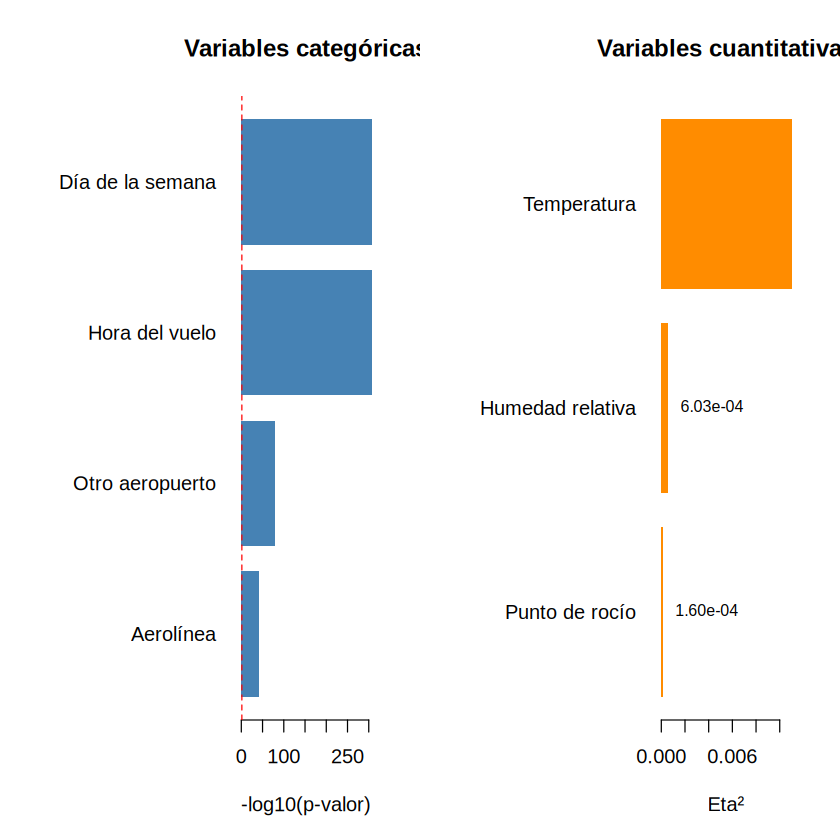

In [18]:
# ============================================================
# 8. ANÁLISIS DESCRIPTIVO CATDES (TRAIN)
# ============================================================

# 1. Preparar datos utilizando exclusivamente TRAIN
datos_catdes <- train_clas %>%
  select(retraso_15_min, all_of(variables_predictoras)) %>%
  mutate(
    retraso_15_min = factor(
      retraso_15_min,
      levels = c(0, 1),
      labels = c("NO_RETRASO", "RETRASO")
    ),
    across(all_of(variables_categoricas), as.factor)
  )

# 2. Ejecutar CATDES
resultado_catdes <- FactoMineR::catdes(
  datos_catdes,
  num.var = 1,
  proba = 0.05,
  na.method = "na.omit"
)

# 3. Mostrar resultados estadísticos
cat("\n===== CATDES: VARIABLES CATEGÓRICAS =====\n")
print(resultado_catdes$test.chi)

cat("\n===== CATDES: VARIABLES CUANTITATIVAS =====\n")
print(resultado_catdes$quanti.var)

# ============================================================
# 4. PREPARAR TABLAS PARA LOS GRÁFICOS
# ============================================================

# Variables categóricas: significación estadística
tabla_chi <- as.data.frame(resultado_catdes$test.chi)
tabla_chi$Variable <- rownames(tabla_chi)

tabla_chi$Variable <- recode(
  tabla_chi$Variable,
  hora_vuelo = "Hora del vuelo",
  dia_semana = "Día de la semana",
  airline_iata = "Aerolínea",
  other_airport_iata = "Otro aeropuerto"
)

# Evitar infinitos cuando p.value = 0
tabla_chi$p.value[tabla_chi$p.value == 0] <- .Machine$double.xmin

tabla_chi$Significancia <- -log10(tabla_chi$p.value)
tabla_chi <- tabla_chi[order(tabla_chi$Significancia), ]

# Variables cuantitativas: Eta²
tabla_eta <- as.data.frame(resultado_catdes$quanti.var)
tabla_eta$Variable <- rownames(tabla_eta)

tabla_eta$Variable <- recode(
  tabla_eta$Variable,
  temperatura_metar = "Temperatura",
  relh = "Humedad relativa",
  punto_rocio_metar = "Punto de rocío"
)

tabla_eta <- tabla_eta[order(tabla_eta$Eta2), ]

# ============================================================
# 5. MOSTRAR LOS DOS GRÁFICOS EN UNA SOLA SALIDA
# ============================================================

par(mfrow = c(1, 2), mar = c(5, 10, 4, 2))

# Gráfico 1: variables categóricas
pos_chi <- barplot(
  tabla_chi$Significancia,
  names.arg = tabla_chi$Variable,
  horiz = TRUE,
  las = 1,
  col = "steelblue",
  border = NA,
  main = "Variables categóricas",
  xlab = "-log10(p-valor)"
)

abline(v = -log10(0.05), lty = 2, col = "red")

# Gráfico 2: variables cuantitativas
pos_eta <- barplot(
  tabla_eta$Eta2,
  names.arg = tabla_eta$Variable,
  horiz = TRUE,
  las = 1,
  col = "darkorange",
  border = NA,
  main = "Variables cuantitativas",
  xlab = "Eta²"
)

text(
  x = tabla_eta$Eta2,
  y = pos_eta,
  labels = format(tabla_eta$Eta2, scientific = TRUE, digits = 3),
  pos = 4,
  cex = 0.8
)

# Restaurar configuración gráfica
par(mfrow = c(1, 1), mar = c(5, 4, 4, 2))


## 9. Seleccionar el umbral de clasificación en VALIDACIÓN

Se ajusta una regresión logística con TRAIN y se calcula su probabilidad en VALIDACIÓN. El umbral se elige maximizando F1; en caso de empate se prioriza la precisión. El TEST FINAL no participa en esta decisión.

In [8]:
calcular_auc <- function(real, score) {
  ok <- !is.na(real) & is.finite(score)
  real <- as.integer(real[ok])
  score <- score[ok]
  n1 <- sum(real == 1)
  n0 <- sum(real == 0)
  if (n1 == 0 || n0 == 0) return(NA_real_)
  r <- rank(score, ties.method = "average")
  (sum(r[real == 1]) - n1 * (n1 + 1) / 2) / (n1 * n0)
}

calcular_ap <- function(real, score) {
  ok <- !is.na(real) & is.finite(score)
  real <- as.integer(real[ok])
  score <- score[ok]
  if (sum(real == 1) == 0) return(NA_real_)
  orden <- order(score, decreasing = TRUE)
  y <- real[orden]
  precision_acumulada <- cumsum(y) / seq_along(y)
  mean(precision_acumulada[y == 1])
}

calcular_metricas_binarias <- function(real, score, umbral) {
  real <- as.integer(real)
  pred <- as.integer(score >= umbral)
  tp <- sum(pred == 1 & real == 1)
  tn <- sum(pred == 0 & real == 0)
  fp <- sum(pred == 1 & real == 0)
  fn <- sum(pred == 0 & real == 1)

  precision <- if (tp + fp > 0) tp / (tp + fp) else 0
  recall <- if (tp + fn > 0) tp / (tp + fn) else 0
  especificidad <- if (tn + fp > 0) tn / (tn + fp) else 0
  f1 <- if (precision + recall > 0) {
    2 * precision * recall / (precision + recall)
  } else 0

  data.frame(
    umbral = umbral,
    AUC = calcular_auc(real, score),
    AP = calcular_ap(real, score),
    accuracy = mean(pred == real),
    precision = precision,
    recall = recall,
    especificidad = especificidad,
    F1 = f1,
    alertas_pct = mean(pred == 1) * 100,
    TP = tp, TN = tn, FP = fp, FN = fn
  )
}

# Quitar columnas constantes en TRAIN.
constantes_train <- vapply(
  seq_len(ncol(x_train)),
  function(j) length(unique(x_train[, j])) <= 1,
  logical(1)
)
columnas_logistica <- colnames(x_train)[!constantes_train]

x_train_log <- x_train[, columnas_logistica, drop = FALSE]
x_val_log <- crear_matriz_predictores(
  val_clas, formula_x, columnas_logistica
)

X_train_full <- cbind(Intercept = 1, as.matrix(x_train_log))
X_val_full <- cbind(Intercept = 1, as.matrix(x_val_log))

qr_log <- qr(X_train_full)
idx_log <- qr_log$pivot[seq_len(qr_log$rank)]
columnas_diseno_log <- colnames(X_train_full)[idx_log]

X_train_log <- X_train_full[, columnas_diseno_log, drop = FALSE]
X_val_log <- X_val_full[, columnas_diseno_log, drop = FALSE]

modelo_logistica_validacion <- suppressWarnings(
  stats::glm.fit(
    x = X_train_log,
    y = y_train,
    family = stats::binomial(),
    control = stats::glm.control(maxit = 100)
  )
)

if (!isTRUE(modelo_logistica_validacion$converged) ||
    any(!is.finite(modelo_logistica_validacion$coefficients))) {
  stop("La regresión logística de VALIDACIÓN no convergió correctamente.")
}

prob_val <- as.numeric(
  plogis(X_val_log %*% modelo_logistica_validacion$coefficients)
)

umbrales <- seq(0.005, 0.50, by = 0.005)
tabla_umbrales <- do.call(rbind, lapply(umbrales, function(u) {
  calcular_metricas_binarias(y_val, prob_val, u)
}))

tabla_umbrales <- tabla_umbrales[
  order(-tabla_umbrales$F1, -tabla_umbrales$precision, -tabla_umbrales$recall),
]
row.names(tabla_umbrales) <- NULL
umbral_final <- tabla_umbrales$umbral[1]

cat("===== UMBRAL ELEGIDO EN VALIDACIÓN =====\n")
print(head(tabla_umbrales, 10), row.names = FALSE, digits = 4)
cat("Umbral definitivo:", umbral_final, "\n")

metricas_validacion_umbral <- calcular_metricas_binarias(
  y_val, prob_val, umbral_final
)
print(metricas_validacion_umbral, row.names = FALSE, digits = 4)

===== UMBRAL ELEGIDO EN VALIDACIÓN =====
 umbral    AUC      AP accuracy precision recall especificidad     F1
  0.100 0.6334 0.08135   0.4631   0.09392 0.8721        0.4356 0.1696
  0.105 0.6334 0.08135   0.4681   0.09394 0.8631        0.4416 0.1694
  0.095 0.6334 0.08135   0.4576   0.09364 0.8788        0.4294 0.1692
  0.110 0.6334 0.08135   0.4727   0.09359 0.8507        0.4473 0.1686
  0.090 0.6334 0.08135   0.4521   0.09305 0.8822        0.4232 0.1683
  0.085 0.6334 0.08135   0.4459   0.09239 0.8855        0.4164 0.1673
  0.080 0.6334 0.08135   0.4405   0.09204 0.8911        0.4103 0.1668
  0.115 0.6334 0.08135   0.4773   0.09264 0.8316        0.4535 0.1667
  0.075 0.6334 0.08135   0.4347   0.09145 0.8945        0.4039 0.1659
  0.120 0.6334 0.08135   0.4828   0.09180 0.8126        0.4607 0.1650
 alertas_pct  TP   TN   FP  FN
       58.37 777 5786 7496 114
       57.76 769 5865 7417 122
       59.00 783 5703 7579 108
       57.14 758 5941 7341 133
       59.60 786 5621 7661 105
   

## 10. Entrenar el clasificador final y evaluar TEST

Una vez elegido el umbral en VALIDACIÓN, se vuelve a ajustar la regresión logística con TRAIN + VALIDACIÓN. Se aplica el umbral previamente fijado al conjunto TEST FINAL, que no intervino en el entrenamiento ni en la selección del umbral.

In [9]:
datos_desarrollo <- bind_rows(datos_train, datos_val) %>%
  arrange(fecha_vuelo)

# Preprocesamiento final: las reglas se aprenden con todo el desarrollo.
datos_clas_dev <- datos_desarrollo %>%
  select(retraso_15_min, all_of(variables_predictoras))
datos_clas_test <- datos_test_final %>%
  select(retraso_15_min, all_of(variables_predictoras))

prep_clas_final <- preparar_categorias_temporal(
  datos_clas_dev,
  datos_clas_dev,
  datos_clas_test,
  variables_categoricas = variables_categoricas,
  frecuencia_minima = 2
)

x_clas_dev0 <- crear_matriz_predictores(prep_clas_final$train, formula_x)
constantes_dev <- vapply(
  seq_len(ncol(x_clas_dev0)),
  function(j) length(unique(x_clas_dev0[, j])) <= 1,
  logical(1)
)
columnas_x_clas_final <- colnames(x_clas_dev0)[!constantes_dev]
x_clas_dev <- x_clas_dev0[, columnas_x_clas_final, drop = FALSE]
x_clas_test <- crear_matriz_predictores(
  prep_clas_final$test, formula_x, columnas_x_clas_final
)

y_clas_dev <- as.integer(prep_clas_final$train$retraso_15_min)
y_clas_test <- as.integer(prep_clas_final$test$retraso_15_min)

X_clas_dev_full <- cbind(Intercept = 1, as.matrix(x_clas_dev))
X_clas_test_full <- cbind(Intercept = 1, as.matrix(x_clas_test))

qr_clas_final <- qr(X_clas_dev_full)
idx_clas_final <- qr_clas_final$pivot[seq_len(qr_clas_final$rank)]
columnas_diseno_clas_final <- colnames(X_clas_dev_full)[idx_clas_final]
X_clas_dev <- X_clas_dev_full[, columnas_diseno_clas_final, drop = FALSE]
X_clas_test <- X_clas_test_full[, columnas_diseno_clas_final, drop = FALSE]

modelo_logistica_final <- suppressWarnings(
  stats::glm.fit(
    x = X_clas_dev,
    y = y_clas_dev,
    family = stats::binomial(),
    control = stats::glm.control(maxit = 100)
  )
)

if (!isTRUE(modelo_logistica_final$converged) ||
    any(!is.finite(modelo_logistica_final$coefficients))) {
  stop("La regresión logística final no convergió o produjo coeficientes no finitos.")
}

prob_clas_test <- as.numeric(
  plogis(X_clas_test %*% modelo_logistica_final$coefficients)
)
pred_clas_test <- as.integer(prob_clas_test >= umbral_final)

metricas_clasificacion_test <- calcular_metricas_binarias(
  y_clas_test, prob_clas_test, umbral_final
)
metricas_clasificacion_test$modelo <- "Regresión logística"
metricas_clasificacion_test$filas_test <- length(y_clas_test)
metricas_clasificacion_test$prevalencia_pct <- mean(y_clas_test == 1) * 100

cat("===== CLASIFICACIÓN: TEST FINAL =====\n")
print(metricas_clasificacion_test, row.names = FALSE, digits = 4)

cat("===== MATRIZ DE CONFUSIÓN =====\n")
print(table(
  Predicción = factor(pred_clas_test, levels = c(0, 1)),
  Real = factor(y_clas_test, levels = c(0, 1))
))

===== CLASIFICACIÓN: TEST FINAL =====
 umbral   AUC     AP accuracy precision recall especificidad     F1 alertas_pct
    0.1 0.638 0.3676   0.6035    0.3266 0.6019        0.6039 0.4234       44.59
   TP    TN   FP   FN              modelo filas_test prevalencia_pct
 3602 11327 7428 2382 Regresión logística      24739           24.19
===== MATRIZ DE CONFUSIÓN =====
          Real
Predicción     0     1
         0 11327  2382
         1  7428  3602


## 11. Entrenar el modelo de regresión GBM y evaluar TEST

La regresión se entrena exclusivamente con registros cuya etiqueta es `retraso_15_min = 1`. El objetivo se transforma mediante `log1p()` para reducir la asimetría y la influencia de retrasos extremos. Las predicciones se transforman de vuelta a minutos con `expm1()` y se limita el resultado mínimo a 15 minutos.

In [10]:
train_reg_dev <- datos_desarrollo %>%
  filter(retraso_15_min == 1) %>%
  select(all_of(variables_predictoras), retraso_minutos)

test_reg_final <- datos_test_final %>%
  filter(retraso_15_min == 1) %>%
  select(aena_airport_iata, flight_number, scheduled_local,
         all_of(variables_predictoras), retraso_minutos)

if (nrow(train_reg_dev) == 0 || nrow(test_reg_final) == 0) {
  stop("No hay suficientes vuelos retrasados para entrenar o evaluar la regresión.")
}

prep_reg_final <- preparar_categorias_temporal(
  train_reg_dev,
  train_reg_dev,
  test_reg_final,
  variables_categoricas = variables_categoricas,
  frecuencia_minima = 2
)

x_reg_dev0 <- crear_matriz_predictores(prep_reg_final$train, formula_x)
constantes_reg <- vapply(
  seq_len(ncol(x_reg_dev0)),
  function(j) length(unique(x_reg_dev0[, j])) <= 1,
  logical(1)
)
columnas_x_reg_final <- colnames(x_reg_dev0)[!constantes_reg]
x_reg_dev <- x_reg_dev0[, columnas_x_reg_final, drop = FALSE]
x_reg_test <- crear_matriz_predictores(
  prep_reg_final$test, formula_x, columnas_x_reg_final
)

y_reg_dev <- as.numeric(prep_reg_final$train$retraso_minutos)
y_reg_test <- as.numeric(prep_reg_final$test$retraso_minutos)

if (any(!is.finite(y_reg_dev)) || any(y_reg_dev < 15)) {
  stop("La variable objetivo de TRAIN de regresión contiene valores no válidos.")
}

N_TREES_REG <- 300
set.seed(2026)

datos_gbm_reg_final <- data.frame(
  retraso_log = log1p(y_reg_dev),
  as.data.frame(x_reg_dev),
  check.names = TRUE
)

modelo_gbm_regresion_final <- gbm::gbm(
  retraso_log ~ .,
  data = datos_gbm_reg_final,
  distribution = "gaussian",
  n.trees = N_TREES_REG,
  interaction.depth = 3,
  shrinkage = 0.03,
  n.minobsinnode = 20,
  bag.fraction = 0.5,
  train.fraction = 1,
  verbose = FALSE
)

pred_log_reg_test <- as.numeric(predict(
  modelo_gbm_regresion_final,
  newdata = as.data.frame(x_reg_test),
  n.trees = N_TREES_REG,
  type = "response"
))

pred_minutos_reg_test <- pmax(15, expm1(pred_log_reg_test))

metricas_regresion_test <- data.frame(
  modelo = "GBM log1p",
  filas_test_retrasadas = length(y_reg_test),
  MAE_minutos = mean(abs(y_reg_test - pred_minutos_reg_test)),
  RMSE_minutos = sqrt(mean((y_reg_test - pred_minutos_reg_test)^2))
)

predicciones_regresion_test <- data.frame(
  test_reg_final %>% select(aena_airport_iata, flight_number, scheduled_local),
  retraso_estimado_objetivo = y_reg_test,
  retraso_predicho = pred_minutos_reg_test,
  error_absoluto_minutos = abs(y_reg_test - pred_minutos_reg_test)
)

cat("===== REGRESIÓN: TEST FINAL =====\n")
print(metricas_regresion_test, row.names = FALSE, digits = 4)

===== REGRESIÓN: TEST FINAL =====
    modelo filas_test_retrasadas MAE_minutos RMSE_minutos
 GBM log1p                  5984       33.21         68.2


## 12. Coeficientes e importancia de variables

Se generan tres salidas distintas y no intercambiables:

1. **Coeficientes y odds ratios de la logística:** cada nivel categórico se compara con una categoría de referencia. No son porcentajes de importancia.
2. **Importancia por permutación de la logística:** mide cuánto cae AUC y Average Precision al permutar conjuntamente las columnas de una variable en VALIDACIÓN. Se usa el modelo ajustado en TRAIN, no TEST.
3. **Importancia relativa del GBM de regresión:** `summary.gbm()` reparte la importancia interna del GBM; se agrupan niveles categóricos bajo su variable original.

Estas medidas describen asociación o contribución predictiva, no causalidad.

In [11]:
grupo_variable <- function(v) {
  if (v %in% c("Intercept", "(Intercept)")) return("Intercepto")
  if (v == "temperatura_metar") return("temperatura_metar")
  if (v == "punto_rocio_metar") return("punto_rocio_metar")
  if (v == "relh") return("relh")
  if (startsWith(v, "hora_vuelo")) return("hora_vuelo")
  if (startsWith(v, "dia_semana")) return("dia_semana")
  if (startsWith(v, "airline_iata")) return("airline_iata")
  if (startsWith(v, "other_airport_iata")) return("other_airport_iata")
  "otra"
}

# 12.1 Coeficientes de la logística final.
coef_final <- modelo_logistica_final$coefficients
tabla_coeficientes_logistica <- data.frame(
  termino = names(coef_final),
  variable = vapply(names(coef_final), grupo_variable, character(1)),
  coeficiente_logit = as.numeric(coef_final),
  odds_ratio = exp(as.numeric(coef_final))
)

cat("===== COEFICIENTES NUMÉRICOS DE LA LOGÍSTICA =====\n")
print(
  subset(tabla_coeficientes_logistica,
         variable %in% c("temperatura_metar", "punto_rocio_metar", "relh")),
  row.names = FALSE,
  digits = 4
)

cat("===== 15 COEFICIENTES CATEGÓRICOS DE MAYOR MAGNITUD (REFERENCIA) =====\n")
coef_categoricos <- subset(
  tabla_coeficientes_logistica,
  variable %in% c("hora_vuelo", "dia_semana", "airline_iata", "other_airport_iata")
)
coef_categoricos <- coef_categoricos[
  order(abs(coef_categoricos$coeficiente_logit), decreasing = TRUE),
]
print(head(coef_categoricos, 15), row.names = FALSE, digits = 4)

# 12.2 Importancia por permutación en VALIDACIÓN.
X_perm <- as.matrix(X_val_log)
beta_perm <- as.numeric(modelo_logistica_validacion$coefficients)
grupos_perm <- vapply(colnames(X_perm), grupo_variable, character(1))
score_base_perm <- plogis(drop(X_perm %*% beta_perm))
auc_base_perm <- calcular_auc(y_val, score_base_perm)
ap_base_perm <- calcular_ap(y_val, score_base_perm)

set.seed(2026)
B_PERM <- 10
variables_perm <- setdiff(unique(grupos_perm), c("Intercepto", "otra"))

importancias_logistica <- lapply(variables_perm, function(v) {
  columnas_v <- which(grupos_perm == v)
  caidas_auc <- numeric(B_PERM)
  caidas_ap <- numeric(B_PERM)

  for (b in seq_len(B_PERM)) {
    Xp <- X_perm
    perm <- sample.int(nrow(Xp))
    Xp[, columnas_v] <- X_perm[perm, columnas_v, drop = FALSE]
    score_perm <- plogis(drop(Xp %*% beta_perm))
    caidas_auc[b] <- auc_base_perm - calcular_auc(y_val, score_perm)
    caidas_ap[b] <- ap_base_perm - calcular_ap(y_val, score_perm)
  }

  data.frame(
    variable = v,
    caida_AUC_media = mean(caidas_auc, na.rm = TRUE),
    caida_AP_media = mean(caidas_ap, na.rm = TRUE)
  )
})

tabla_importancia_logistica <- do.call(rbind, importancias_logistica)
tabla_importancia_logistica <- tabla_importancia_logistica[
  order(-tabla_importancia_logistica$caida_AP_media),
]

cat("===== IMPORTANCIA POR PERMUTACIÓN: LOGÍSTICA (VALIDACIÓN) =====\n")
print(tabla_importancia_logistica, row.names = FALSE, digits = 4)

# 12.3 Importancia interna del GBM de regresión, agrupada por variable original.
imp_reg <- summary(
  modelo_gbm_regresion_final,
  n.trees = N_TREES_REG,
  plotit = FALSE
)
imp_reg$variable <- vapply(as.character(imp_reg$var), grupo_variable, character(1))
imp_reg_agrupada <- aggregate(rel.inf ~ variable, data = imp_reg, FUN = sum)
imp_reg_agrupada <- imp_reg_agrupada[order(-imp_reg_agrupada$rel.inf), ]

cat("===== IMPORTANCIA RELATIVA: GBM DE REGRESIÓN =====\n")
print(imp_reg_agrupada, row.names = FALSE, digits = 4)

===== COEFICIENTES NUMÉRICOS DE LA LOGÍSTICA =====
           termino          variable coeficiente_logit odds_ratio
 temperatura_metar temperatura_metar           0.13081     1.1397
 punto_rocio_metar punto_rocio_metar          -0.08894     0.9149
              relh              relh           0.04466     1.0457
===== 15 COEFICIENTES CATEGÓRICOS DE MAYOR MAGNITUD (REFERENCIA) =====
               termino           variable coeficiente_logit odds_ratio
        airline_iataRX       airline_iata            -30.91  3.785e-14
       airline_iataRXI       airline_iata            -30.70  4.641e-14
       airline_iataAZG       airline_iata             16.61  1.630e+07
 other_airport_iataRUH other_airport_iata             16.52  1.489e+07
        airline_iataCY       airline_iata            -15.42  2.008e-07
 other_airport_iataMRU other_airport_iata            -15.33  2.193e-07
        airline_iataBM       airline_iata            -15.19  2.525e-07
      airline_iataOTRA       airline_iata     

## 13. Resumen de evaluación y limitaciones

### Resultados de la última ejecución consolidada (23/10/2026)

Los siguientes valores son los resultados registrados durante la ejecución final comunicada para este proyecto. Al volver a ejecutar el notebook, las métricas se calculan nuevamente y pueden cambiar si la tabla Gold ha sido actualizada retroactivamente.

| Modelo | Métrica | Resultado TEST |
|---|---|---:|
| Regresión logística | AUC | 0,638 |
| Regresión logística | Average Precision | 0,3676 |
| Regresión logística | Precisión (umbral 0,10) | 32,66 % |
| Regresión logística | Recall (umbral 0,10) | 60,19 % |
| Regresión logística | F1 (umbral 0,10) | 0,4234 |
| GBM logarítmico | MAE | 33,21 minutos |
| GBM logarítmico | RMSE | 68,20 minutos |

### Comparación exploratoria realizada durante el desarrollo

En tres ventanas temporales de desarrollo, las medias observadas para clasificación fueron: GBM AUC 0,3534 / AP 0,08223; regresión logística completa AUC 0,4796 / AP 0,10414; regresión logística reducida AUC 0,4586 / AP 0,1027. La logística completa se mantuvo como opción final, aunque las métricas medias de ventana indicaron una generalización débil e inestable.

En regresión, el GBM logarítmico obtuvo MAE medio 26,5 y RMSE medio 50,4 minutos en las tres ventanas; la referencia de mediana obtuvo MAE medio 25,8 y RMSE medio 51,9. Por tanto, la ventaja depende de la métrica: la referencia fue mejor en MAE y GBM en RMSE.

### Limitaciones que deben declararse

- La etiqueta se basa en `estimated_local - scheduled_local`, no necesariamente en el retraso real observado.
- La proporción de etiquetas positivas varió entre ventanas y fue 24,19 % en el TEST final; la distribución temporal cambia y puede afectar a la generalización.
- Con umbral 0,10, la logística detectó 60,19 % de los positivos en TEST, pero su precisión fue 32,66 %: hay falsas alarmas relevantes. El modelo ofrece una señal de riesgo, no una confirmación de retraso.
- El GBM de regresión se evalúa solo sobre casos positivos; MAE y RMSE se refieren a ese subconjunto.
- CATDES y las importancias describen asociaciones; no prueban causalidad.
- Los resultados corresponden a los datos disponibles hasta el 19/10/2026 y deben interpretarse dentro de ese periodo.

## 14. Exportar resultados y modelos

Se exportan el RDS final, métricas, coeficientes e importancias. No se exportan credenciales. Los CSV de métricas y predicciones son artefactos de ejecución: antes de subirlos a Git, comprobar si contienen información que deba mantenerse fuera del repositorio.

In [12]:
artefacto_aeropredict_final <- list(
  version = "1.0.0",
  fecha_corte_datos = as.character(fecha_corte_datos),
  filas_desarrollo = nrow(datos_desarrollo),
  fecha_inicio_test = as.character(min(datos_test_final$fecha_vuelo)),
  fecha_fin_test = as.character(max(datos_test_final$fecha_vuelo)),
  variables_predictoras = variables_predictoras,
  variables_categoricas = variables_categoricas,
  formula_predictoras = formula_x,
  frecuencia_minima_categoria = 2,
  dominios_temporales = dominios_temporales,
  definicion_objetivo = paste(
    "retraso_15_min = 1 si retraso_minutos >= 15;",
    "retraso_minutos procede de estimated_local - scheduled_local",
    "y puede no representar un retraso real observado."
  ),
  clasificacion = list(
    algoritmo = "Regresión logística binomial",
    coeficientes = modelo_logistica_final$coefficients,
    columnas_matriz = columnas_x_clas_final,
    columnas_diseno = columnas_diseno_clas_final,
    umbral = umbral_final,
    reglas_categorias = prep_clas_final$reglas
  ),
  regresion = list(
    algoritmo = "GBM gaussiano sobre log1p(retraso_minutos)",
    modelo = modelo_gbm_regresion_final,
    n.trees = N_TREES_REG,
    columna_objetivo_transformada = "retraso_log",
    suelo_prediccion_minutos = 15,
    columnas_matriz = columnas_x_reg_final,
    reglas_categorias = prep_reg_final$reglas
  ),
  metricas_test = list(
    clasificacion = metricas_clasificacion_test,
    regresion = metricas_regresion_test
  )
)

saveRDS(
  artefacto_aeropredict_final,
  file = "aeropredict_modelos_finales_v1.rds"
)

write.csv(
  metricas_clasificacion_test,
  "aeropredict_metricas_clasificacion_final.csv",
  row.names = FALSE,
  fileEncoding = "UTF-8"
)
write.csv(
  metricas_regresion_test,
  "aeropredict_metricas_regresion_final.csv",
  row.names = FALSE,
  fileEncoding = "UTF-8"
)
write.csv(
  tabla_coeficientes_logistica,
  "aeropredict_coeficientes_logistica.csv",
  row.names = FALSE,
  fileEncoding = "UTF-8"
)
write.csv(
  tabla_importancia_logistica,
  "aeropredict_importancia_logistica_validacion.csv",
  row.names = FALSE,
  fileEncoding = "UTF-8"
)
write.csv(
  imp_reg_agrupada,
  "aeropredict_importancia_gbm_regresion.csv",
  row.names = FALSE,
  fileEncoding = "UTF-8"
)
write.csv(
  data.frame(
    scheduled_local = as.character(test_clas$scheduled_local),
    flight_number = test_clas$flight_number,
    aena_airport_iata = test_clas$aena_airport_iata,
    retraso_15_min_real = y_clas_test,
    probabilidad_retraso = prob_clas_test,
    prediccion_retraso_15_min = pred_clas_test,
    umbral_aplicado = umbral_final
  ),
  "aeropredict_predicciones_clasificacion_test.csv",
  row.names = FALSE,
  fileEncoding = "UTF-8"
)
write.csv(
  predicciones_regresion_test,
  "aeropredict_predicciones_regresion_test.csv",
  row.names = FALSE,
  fileEncoding = "UTF-8"
)

# Verificación de lectura del artefacto y reproducción de predicciones.
artefacto_verificado <- readRDS("aeropredict_modelos_finales_v1.rds")

prob_reconstruida <- as.numeric(
  plogis(X_clas_test %*% artefacto_verificado$clasificacion$coeficientes)
)
pred_log_reconstruida <- as.numeric(predict(
  artefacto_verificado$regresion$modelo,
  newdata = as.data.frame(x_reg_test),
  n.trees = artefacto_verificado$regresion$n.trees,
  type = "response"
))
pred_min_reconstruida <- pmax(
  artefacto_verificado$regresion$suelo_prediccion_minutos,
  expm1(pred_log_reconstruida)
)

stopifnot(
  isTRUE(all.equal(prob_clas_test, prob_reconstruida, tolerance = 1e-10)),
  isTRUE(all.equal(pred_minutos_reg_test, pred_min_reconstruida, tolerance = 1e-10))
)

cat("RDS guardado y verificado: aeropredict_modelos_finales_v1.rds\n")
cat("Las predicciones reproducidas desde el RDS coinciden.\n")
cat("Archivos CSV de métricas, coeficientes, importancias y predicciones guardados.\n")

RDS guardado y verificado: aeropredict_modelos_finales_v1.rds
Las predicciones reproducidas desde el RDS coinciden.
Archivos CSV de métricas, coeficientes, importancias y predicciones guardados.
